In [1]:
## Open pickle files 

In [1]:
from climada_petals.hazard import TCForecast
import logging
import datetime
import os
import numpy as np
import geopandas as gpd

In [2]:
#pip install -e .

In [3]:
###SUBNATIONAL DIVISION 
import geopandas as gpd
geofile_MOZ = '/cluster/work/climate/gespejo/data/infrastructure/Mozambique_results_MOZ/gadm41_MOZ_shp/gadm41_MOZ_1.shp'
gadm_MOZ = gpd.read_file(geofile_MOZ)

In [4]:
### CREATE POINTS FOR EVERY CI AND PEOPLE 
from climada_petals.hazard.IMP_TRACKFORECAST import convert_to_geodf
gadm_MOZ_gdf = convert_to_geodf(gadm_MOZ, ['NAME_1', 'geometry'])

In [5]:
import pickle 

In [6]:
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/impp1_disrupted.pkl', 'rb') as file:
    impp1_disrupted = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/impp1.pkl', 'rb') as file:
    impp1 = pickle.load(file)

In [7]:
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/disrupted_hospitals.pkl', 'rb') as file:
    disrupted_hospitals = pickle.load(file) 

In [8]:
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/disrupted_schools.pkl', 'rb') as file:
    disrupted_schools = pickle.load(file)

In [9]:
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/rd2_disrupted.pkl', 'rb') as file:
    rd2_disrupted = pickle.load(file)

In [10]:
##################### POPULATION 
from climada.entity.exposures.base import Exposures
#from climada.entity.exposures.base import Exposures
#Exposures.from_raster(path_cntry)
gdf_worldpop_MOZ = Exposures.from_raster('/cluster/work/climate/gespejo/data/infrastructure/population/moz_ppp_2020_1km_Aggregated_UNadj.tif')
#(exposure_pp.gdf.value==0).all()
#exposure_pp_MOZ.gdf
gdf_worldpop_MOZ.set_geometry_points()
###roads original
import geopandas as gpd
gdf_roads_MOZ = gpd.read_feather('/cluster/work/climate/gespejo/data/infrastructure/Mozambique_results_MOZ_2023/road')
# Rename the 'value' column to 'people'
## This one I should do anyway for the nex 
gdf_worldpop_MOZ.gdf.rename(columns={'value': 'people'}, inplace=True)

In [12]:
disrupted_hospitals ['imph2_MOZ_new_FREDDY_20230306120000']

,latitude,longitude,n_ensemble_members,geometry,levels
0,-17.875456,36.881978,29,POINT (36.88198 -17.87546),2
1,-19.746900,34.860563,6,POINT (34.86056 -19.74690),2
2,-19.363976,34.574852,6,POINT (34.57485 -19.36398),1
3,-19.618176,34.741218,6,POINT (34.74122 -19.61818),1
4,-19.687157,34.760013,6,POINT (34.76001 -19.68716),1
...,...,...,...,...,...
278,-17.819074,36.946705,29,POINT (36.94671 -17.81907),4
279,-16.840426,36.987009,23,POINT (36.98701 -16.84043),4
280,-16.154781,33.583681,5,POINT (33.58368 -16.15478),4
281,-15.768335,36.021872,12,POINT (36.02187 -15.76834),1


In [22]:
###only the hospitals plots no layers in the background

In [21]:
def plot_disruption_map_with_hospital_levels_only_nolatlong(
    disrupted_hospitals, gadm_MOZ, output_dir
):
    import os
    import matplotlib.pyplot as plt
    import matplotlib as mpl
    import geopandas as gpd
    import numpy as np
    from shapely.geometry import Point

    os.makedirs(output_dir, exist_ok=True)

    # shape by hospital level
    level_markers = {1: 'o', 2: 's', 3: '^', 4: 'D'}
    level_style = {1: {'s': 24}, 2: {'s': 24}, 3: {'s': 24}, 4: {'s': 24}}  # tweak size if you like

    # colormap = truncated viridis; range 5..51 (same as roads)
    def truncate_cmap(cmap_name='viridis', minval=0.2, maxval=1.0, n=256):
        base = mpl.colormaps[cmap_name]
        new_colors = base(np.linspace(minval, maxval, n))
        return mpl.colors.ListedColormap(new_colors)

    cmap = truncate_cmap('viridis', 0.2, 1.0)
    norm = mpl.colors.Normalize(vmin=5, vmax=51)

    gadm_MOZ = gadm_MOZ.to_crs("EPSG:4326")

    for hosp_key in disrupted_hospitals.keys():
        if not hosp_key.startswith("imph2_MOZ_new_FREDDY_"):
            continue

        try:
            time_id = hosp_key.split("_")[-1]
            df = disrupted_hospitals[hosp_key].copy()

            # to GeoDataFrame
            df['geometry'] = [Point(lon, lat) for lat, lon in zip(df['latitude'], df['longitude'])]
            gdf_hosp = gpd.GeoDataFrame(df, geometry='geometry', crs="EPSG:4326")
            gdf_hosp['levels'] = gdf_hosp['levels'].astype(int)

            fig, ax = plt.subplots(figsize=(10, 10))
            gadm_MOZ.plot(ax=ax, color='white', edgecolor='black', zorder=0)

            # --- filled markers colored by ensemble, NO outline ---
            for level in sorted(gdf_hosp['levels'].dropna().unique()):
                if level not in level_markers:
                    continue
                sub = gdf_hosp[gdf_hosp['levels'] == level]
                vals = sub['n_ensemble_members'].to_numpy()
                fill_cols = cmap(norm(vals))                     # colors by ensemble
                ax.scatter(
                    sub.geometry.x, sub.geometry.y,
                    marker=level_markers[level],
                    s=level_style[level]['s'],
                    facecolors=fill_cols,                        # FILLED by ensemble color
                    edgecolors='none',                           # <-- no contour
                    alpha=0.95,
                    zorder=5
                )

            # extent & clean axes
            ax.set_xlim(32, 42)
            ax.set_ylim(-20, -14)
            ax.set_aspect('equal', adjustable='box')
            ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(''); ax.set_ylabel('')

            # (optional) on-map colorbar – comment out if you prefer separate legend file
            # sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
            # cbar = plt.colorbar(sm, ax=ax, fraction=0.035, pad=0.02, orientation='horizontal')
            # cbar.set_label('Disrupted Ensemble Members (Hospitals)')

            plt.tight_layout()
            fname = os.path.join(
                output_dir, f'disruption_hospitals_{time_id}_hospitals_only_ensemble.png'
            )
            plt.savefig(fname, dpi=2000)
            #plt.close(fig)

        except Exception as e:
            print(f"Error processing {hosp_key}: {e}")

In [22]:
output_dir = "/cluster/home/gespejo/MOZ_struc_plots_Freddy/"

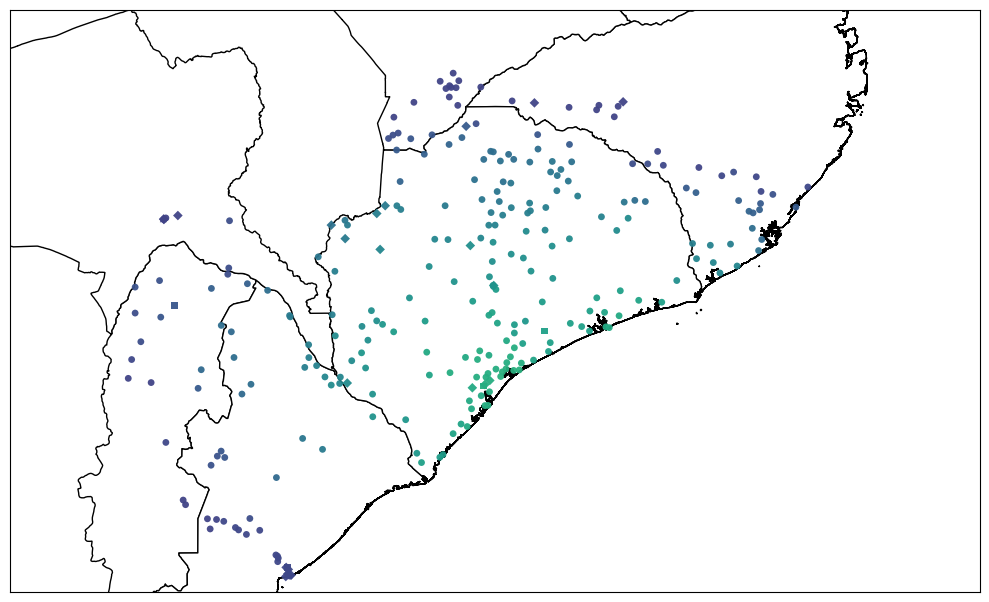

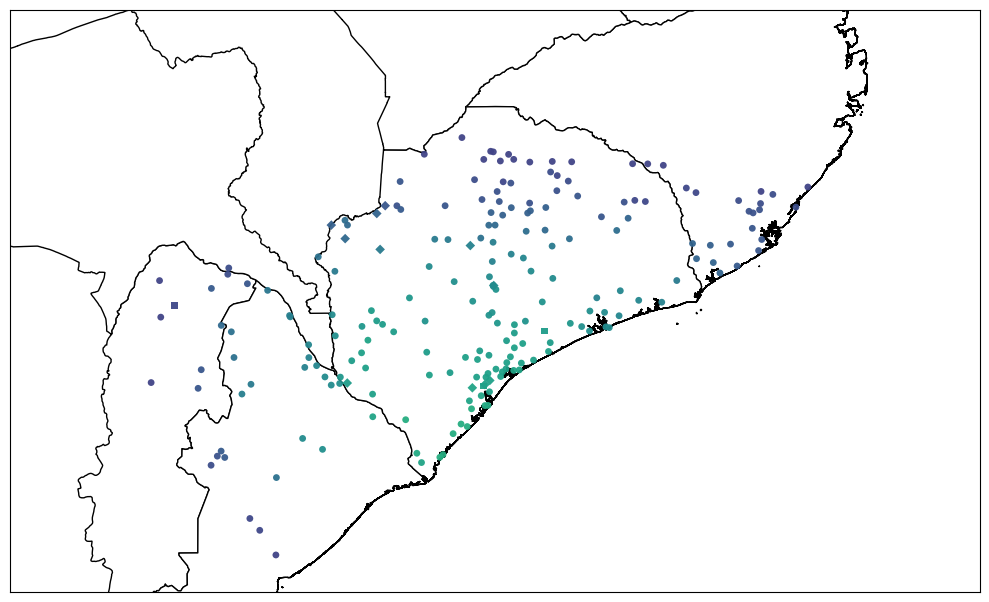

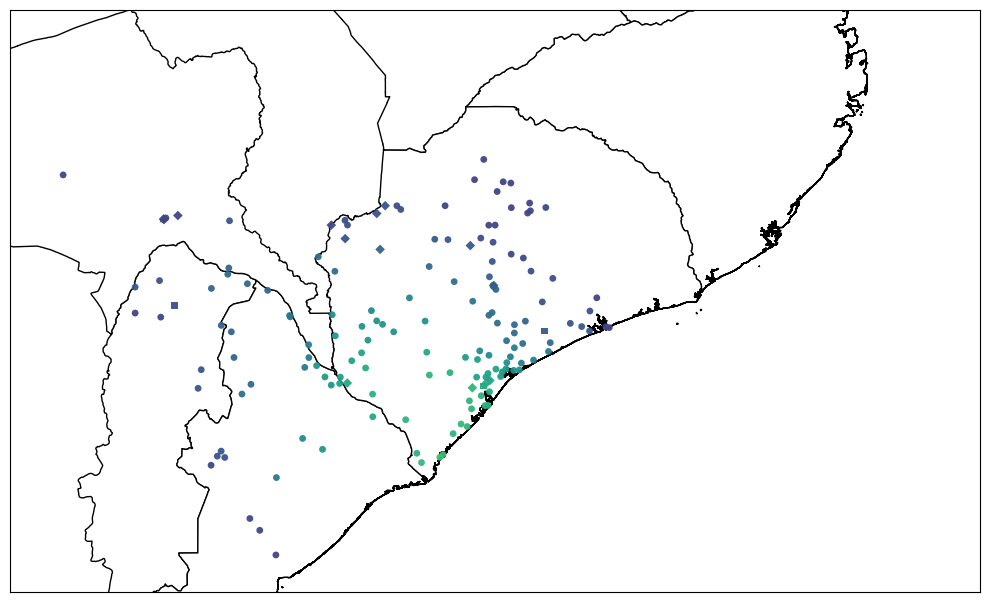

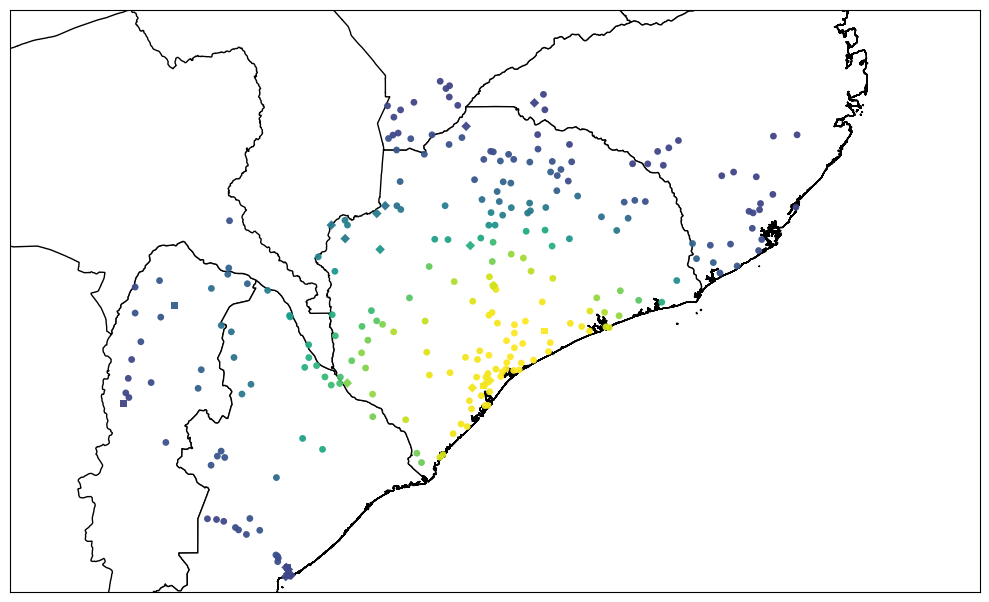

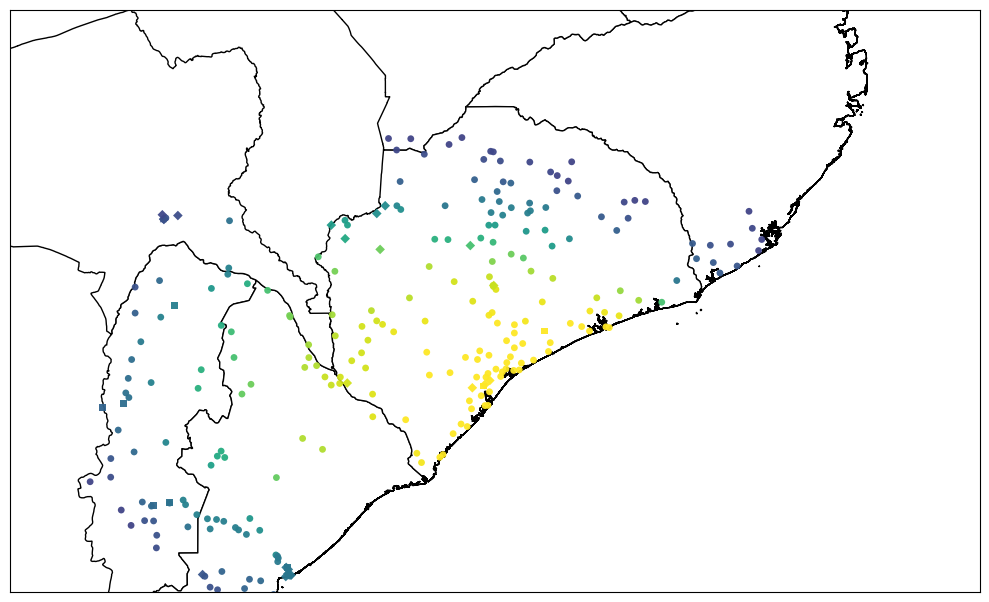

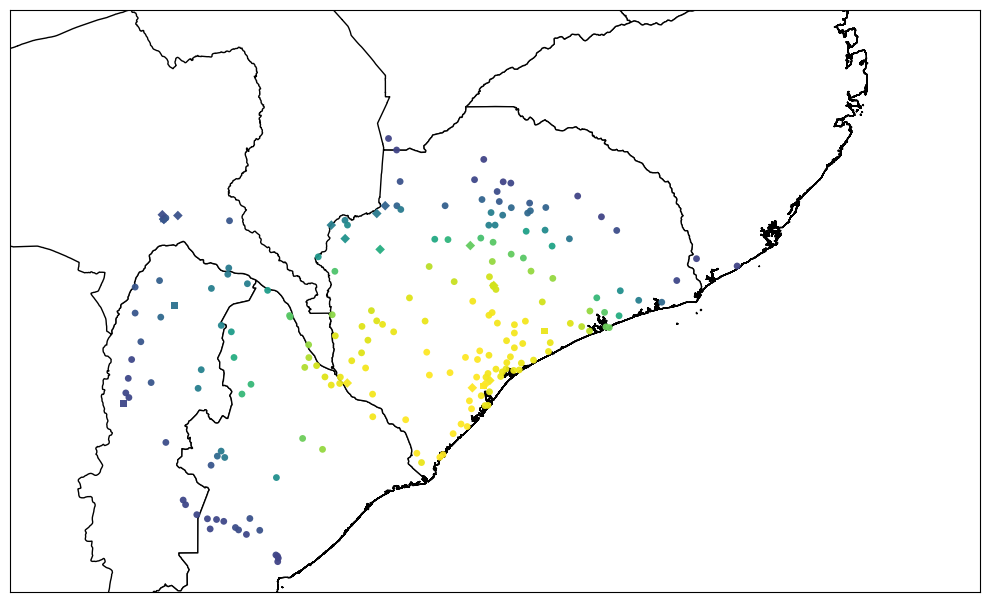

In [23]:
plot_disruption_map_with_hospital_levels_only_nolatlong(disrupted_hospitals, gadm_MOZ, output_dir)

In [24]:
## this one is the last correct used code the others are optional 
import os

def plot_disruption_map_leveltype_nolatlong(disrupted_hospitals, gadm_MOZ, output_dir):
    import os
    import matplotlib.pyplot as plt
    import geopandas as gpd
    import numpy as np
    from datetime import datetime
    from shapely.geometry import Point

    os.makedirs(output_dir, exist_ok=True)

    # Marker style per hospital level
    level_markers = {1: 'o', 2: 's', 3: '^', 4: 'D'}
    level_style = {
        1: {'alpha': 0.8, 'edgecolor': 'indigo',          'facecolor': 'indigo',          's': 20, 'zorder': 5},
        2: {'alpha': 0.8, 'edgecolor': 'mediumslateblue', 'facecolor': 'mediumslateblue', 's': 20, 'zorder': 5},
        3: {'alpha': 0.8, 'edgecolor': 'darkmagenta',     'facecolor': 'darkmagenta',     's': 20, 'zorder': 5},
        4: {'alpha': 0.8, 'edgecolor': 'mediumvioletred', 'facecolor': 'mediumvioletred', 's': 20, 'zorder': 5},
    }

    gadm_MOZ = gadm_MOZ.to_crs("EPSG:4326")

    for hosp_key in disrupted_hospitals.keys():
        if not hosp_key.startswith("imph2_MOZ_new_FREDDY_"):
            continue

        try:
            time_id = hosp_key.split("_")[-1]
            gdf_hosp = disrupted_hospitals[hosp_key].copy()

            # to GeoDataFrame
            gdf_hosp['geometry'] = gdf_hosp.apply(lambda row: Point(row['longitude'], row['latitude']), axis=1)
            gdf_hosp = gpd.GeoDataFrame(gdf_hosp, geometry='geometry', crs="EPSG:4326")
            gdf_hosp['levels'] = gdf_hosp['levels'].astype(int)

            # Title from timestamp (keep or remove as you wish)
            dt_obj = datetime.strptime(time_id, "%Y%m%d%H%M%S")
            formatted_date = dt_obj.strftime("forecast date: %a %d %B %Y %H UTC")

            # Plot
            fig, ax = plt.subplots(figsize=(10, 10))
            gadm_MOZ.plot(ax=ax, color='white', edgecolor='black', zorder=0)

            # Hospital markers by level
            for level in sorted(gdf_hosp['levels'].dropna().unique()):
                if level in level_markers:
                    level_df = gdf_hosp[gdf_hosp['levels'] == level]
                    ax.scatter(level_df.geometry.x, level_df.geometry.y,
                               marker=level_markers[level], **level_style[level])

            # extent and clean axes
            ax.set_xlim(32, 42)
            ax.set_ylim(-20, -14)
            ax.set_aspect('equal', adjustable='box')

            # remove axis labels & ticks
            ax.set_xlabel('')
            ax.set_ylabel('')
            ax.set_xticks([])
            ax.set_yticks([])

            # optional: keep title, or comment next line to remove it
            #ax.set_title(f'{formatted_date}', fontsize=30)

            plt.tight_layout()
            filename = os.path.join(output_dir, f'disruption_hospitals_{time_id}_hospitals_only.png')
            plt.savefig(filename, dpi=2000)
            plt.close()

        except Exception as e:
            print(f"Error processing {hosp_key}: {e}")

In [25]:
impp1_disrupted ['impp1_MOZ_FREDDY_20230311120000'] ['people'].max()

7341

In [ ]:
### schools 

In [31]:
import os
import matplotlib.pyplot as plt
import matplotlib as mpl
import geopandas as gpd
from shapely.geometry import Point

def plot_disruption_schools_only_nolatlong(disrupted_schools, gadm_MOZ, output_dir):
    """
    Plots schools as filled markers whose color encodes n_ensemble_members.
    - Colormap: truncated 'viridis' (0.2..1.0), normalized to 5..51 (to match your roads legend).
    - No axis ticks/labels; map cropped to Mozambique extent you used.
    - No outlines around points (edgecolors='none').
    """
    os.makedirs(output_dir, exist_ok=True)
    gadm_MOZ = gadm_MOZ.to_crs("EPSG:4326")

    # --- colormap setup (same as roads legend) ---
    def truncate_cmap(cmap_name='viridis', minval=0.2, maxval=1.0, n=256):
        base = mpl.colormaps[cmap_name]
        new_colors = base(np.linspace(minval, maxval, n))
        return mpl.colors.ListedColormap(new_colors)

    cmap = truncate_cmap('viridis', 0.2, 1.0)
    norm = mpl.colors.Normalize(vmin=5, vmax=51)   # adjust if your range differs

    for key in disrupted_schools.keys():
        # keep only your FREDDY keys; adapt the prefix if needed
        if not key.startswith("ed2_MOZ_new_FREDDY_"):
            continue

        try:
            time_id = key.split("_")[-1]
            df = disrupted_schools[key].copy()

            # ensure geometry exists; if not, try to build from lon/lat
            if 'geometry' not in df.columns:
                if {'longitude', 'latitude'}.issubset(df.columns):
                    df['geometry'] = [Point(lon, lat) for lon, lat in zip(df['longitude'], df['latitude'])]
                else:
                    print(f"Missing geometry and lon/lat in {key} — skipping.")
                    continue

            gdf = gpd.GeoDataFrame(df, geometry='geometry', crs="EPSG:4326")

            # must have n_ensemble_members
            if 'n_ensemble_members' not in gdf.columns:
                print(f"Missing 'n_ensemble_members' in {key} — skipping.")
                continue

            vals = gdf['n_ensemble_members'].to_numpy()
            colors = cmap(norm(vals))

            fig, ax = plt.subplots(figsize=(10, 10))
            gadm_MOZ.plot(ax=ax, color='white', edgecolor='black', zorder=0)

            # plot filled points colored by ensemble; NO outline
            gdf.plot(
                ax=ax,
                color=colors,
                edgecolor='none',
                markersize=18,   # tweak size as you prefer (e.g., 14–26)
                alpha=0.95,
                zorder=3
            )

            # map extent & clean axes
            ax.set_xlim(32, 42)
            ax.set_ylim(-20, -14)
            ax.set_aspect('equal', adjustable='box')
            ax.set_title('')
            ax.set_xlabel(''); ax.set_ylabel('')
            ax.set_xticks([]); ax.set_yticks([])
            ax.grid(False)

            plt.tight_layout()
            out_png = os.path.join(output_dir, f'disruption_schools_{time_id}_schools_only_ensemble.png')
            plt.savefig(out_png, dpi=2000)
            #plt.close(fig)

        except Exception as e:
            print(f"Error processing {key}: {e}")

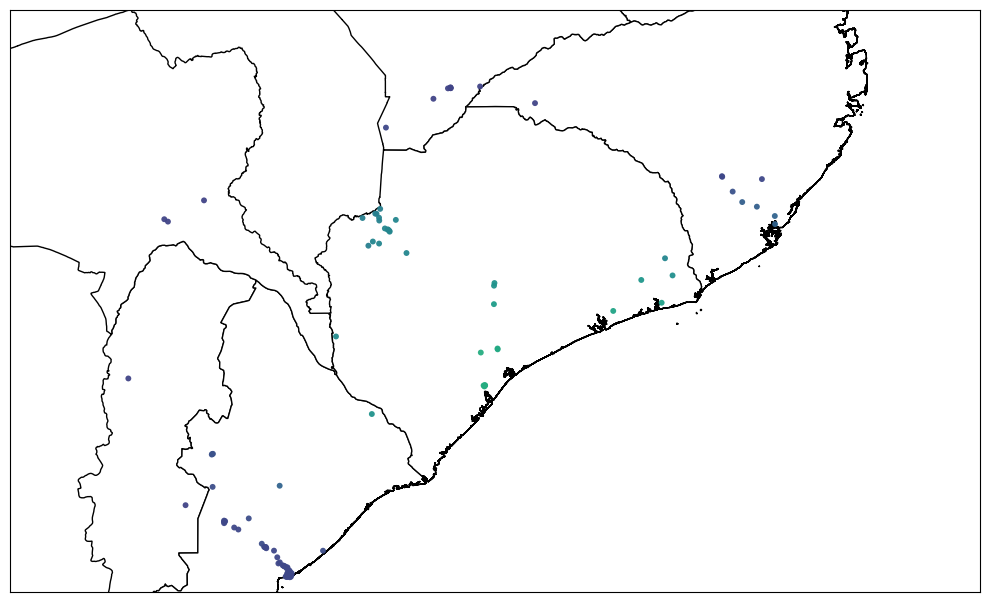

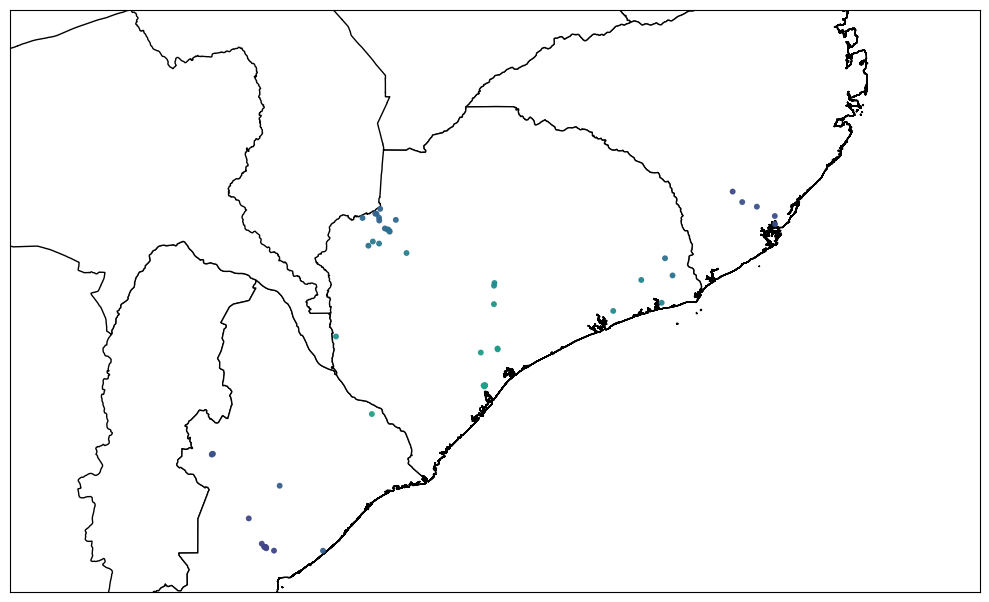

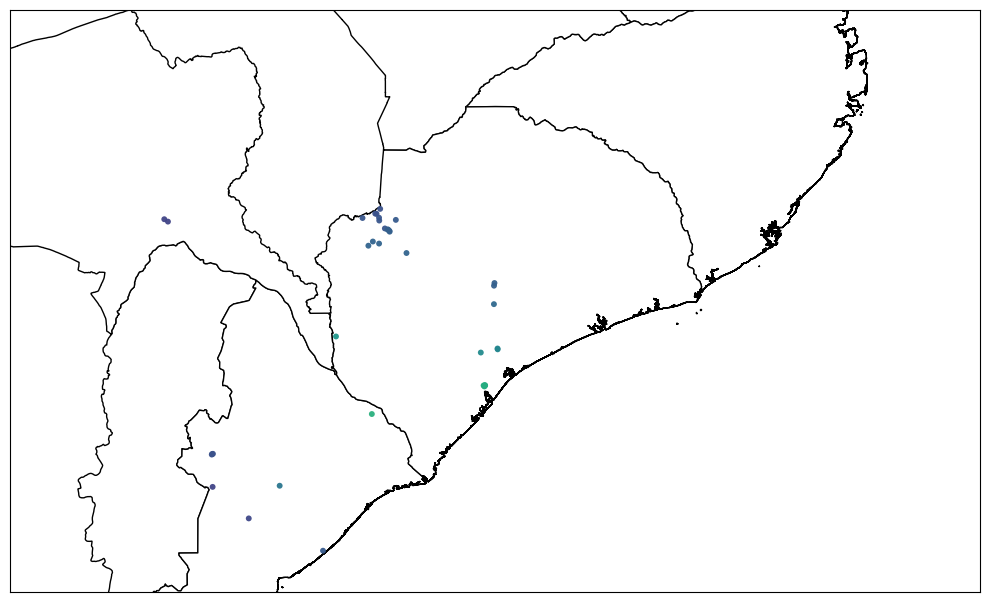

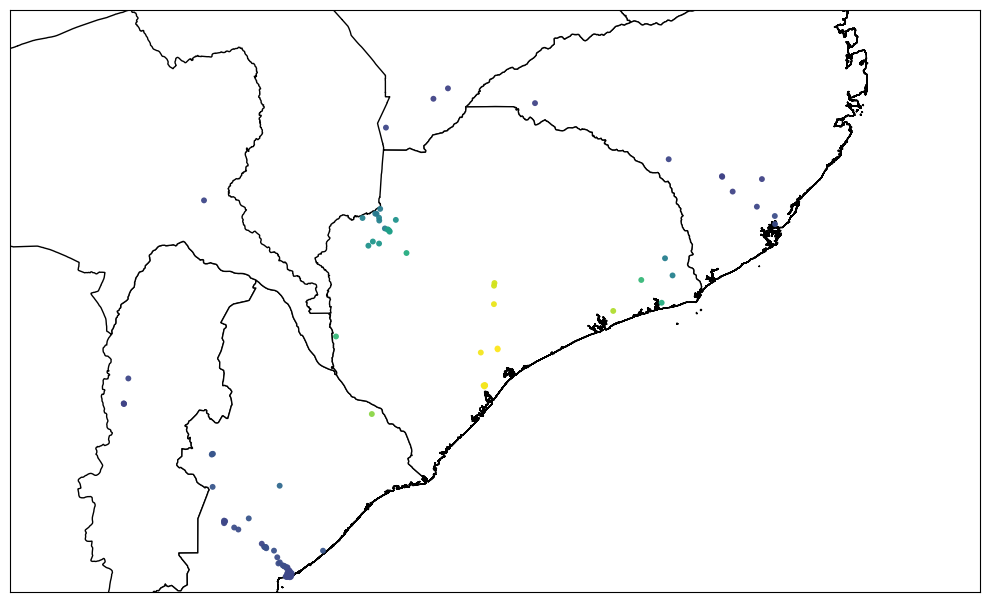

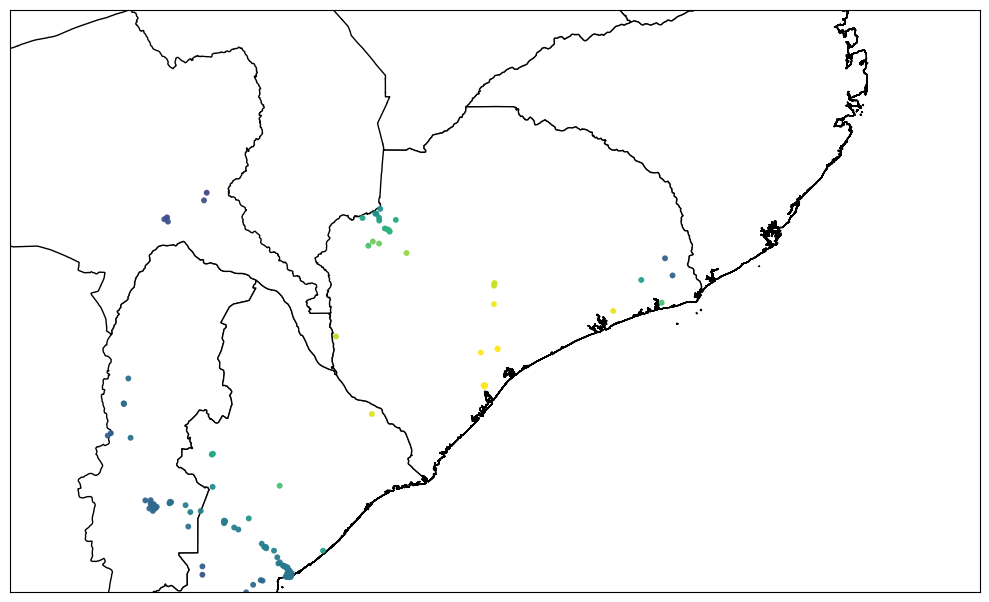

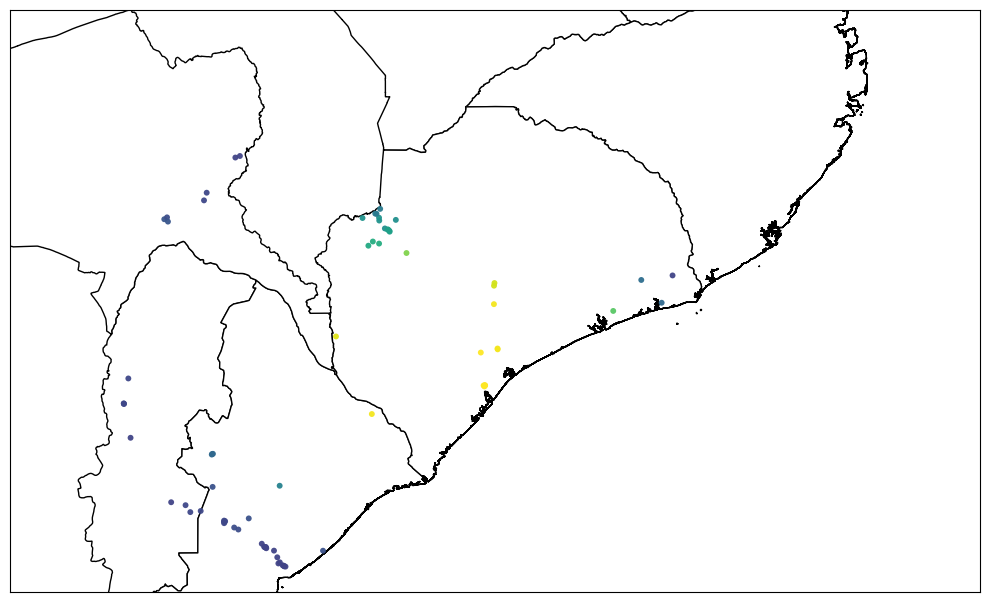

In [32]:
plot_disruption_schools_only_nolatlong(disrupted_schools, gadm_MOZ, output_dir)

In [ ]:
### Road 

In [70]:
import os
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import BoundaryNorm, ListedColormap
import geopandas as gpd
import numpy as np
from datetime import datetime

def truncate_colormap(cmap_name, minval=0.2, maxval=1.0, n=256):
    cmap = plt.get_cmap(cmap_name)
    return ListedColormap(cmap(np.linspace(minval, maxval, n)))

def plot_road_disruption(rd2_disrupted, impp1_direct, impp1_disrupted, gadm_MOZ, output_dir):
    os.makedirs(output_dir, exist_ok=True)

    gadm_MOZ = gadm_MOZ.to_crs("EPSG:4326")
    cmap_purple = ListedColormap(plt.get_cmap("Purples")(np.linspace(0.3, 1.0, 6)))
    cmap_green = ListedColormap(plt.get_cmap("Greens")(np.linspace(0.3, 1.0, 6)))
    cmap_road = truncate_colormap('viridis', 0.2, 1.0)

    for key in rd2_disrupted:
        impp1_key = f"impp1_MOZ_FREDDY_{key}"
        if impp1_key not in impp1_direct or impp1_key not in impp1_disrupted:
            print(f"Skipping {key} due to missing impp1 data.")
            continue

        try:
            gdf_base = impp1_direct[impp1_key].to_crs("EPSG:4326")
            gdf_overlay = impp1_disrupted[impp1_key].to_crs("EPSG:4326")
            roads_df = rd2_disrupted[key].copy()

            if 'geometry_orig' not in roads_df.columns or 'n_ensemble_members' not in roads_df.columns:
                print(f"Skipping {key}: 'geometry_orig' or 'n_ensemble_members' not found.")
                continue

            roads_df = gpd.GeoDataFrame(roads_df, geometry=roads_df['geometry_orig'], crs="EPSG:4326")
            roads_df = roads_df[roads_df['n_ensemble_members'] >= 5]

            gdf_base = gpd.sjoin(gdf_base, gadm_MOZ[['geometry']], how='inner', predicate='within').drop(columns='index_right')
            gdf_overlay = gpd.sjoin(gdf_overlay, gadm_MOZ[['geometry']], how='inner', predicate='within').drop(columns='index_right')
            roads_df = gpd.sjoin(roads_df, gadm_MOZ[['geometry']], how='inner', predicate='intersects').drop(columns='index_right')

            gdf_base = gdf_base[gdf_base['people'] > 0]
            gdf_overlay = gdf_overlay[gdf_overlay['people'] > 0]

            vmax_base = gdf_base['people'].max() if not gdf_base.empty else 1
            vmax_overlay = gdf_overlay['people'].max() if not gdf_overlay.empty else 1

            base_bins = np.linspace(0, vmax_base, 7)
            overlay_bins = np.linspace(0, vmax_overlay, 7)

            norm_base = BoundaryNorm(base_bins, cmap_purple.N, clip=True)
            norm_overlay = BoundaryNorm(overlay_bins, cmap_green.N, clip=True)
            norm_road = mcolors.Normalize(vmin=5, vmax=51)

            base_colors = [cmap_purple(norm_base(val)) for val in gdf_base['people']]
            overlay_colors = [cmap_green(norm_overlay(val)) for val in gdf_overlay['people']]

            dt_obj = datetime.strptime(key, "%Y%m%d%H%M%S")
            formatted_date = dt_obj.strftime("forecast date: %a %d %B %Y %H UTC")

            fig, ax = plt.subplots(figsize=(10, 10))
            gadm_MOZ.plot(ax=ax, color='white', edgecolor='black', zorder=0)
            gdf_base.plot(ax=ax, markersize=10, color=base_colors, edgecolor='none', alpha=0.85, zorder=1)
            gdf_overlay.plot(ax=ax, markersize=10, color=overlay_colors, edgecolor='none', alpha=0.85, zorder=2)
            roads_df.plot(ax=ax, column='n_ensemble_members', cmap=cmap_road, linewidth=1.5, alpha=0.8, zorder=3)

            sm_base = plt.cm.ScalarMappable(cmap=cmap_purple, norm=norm_base)
            sm_base.set_array([])
            cb1 = plt.colorbar(sm_base, ax=ax, orientation='horizontal', pad=0.02, shrink=0.6)
            cb1.set_label('People direct affected')
            cb1.set_ticks(base_bins)
            cb1.ax.tick_params(labelsize=10)

            sm_overlay = plt.cm.ScalarMappable(cmap=cmap_green, norm=norm_overlay)
            sm_overlay.set_array([])
            cb2 = plt.colorbar(sm_overlay, ax=ax, orientation='horizontal', pad=0.08, shrink=0.6)
            cb2.set_label('People disrupted cat.1')
            cb2.set_ticks(overlay_bins)
            cb2.ax.tick_params(labelsize=10)

            sm_road = plt.cm.ScalarMappable(cmap=cmap_road, norm=norm_road)
            sm_road.set_array([])
            cb3 = plt.colorbar(sm_road, ax=ax, orientation='vertical', pad=0.01, shrink=0.5)
            cb3.set_label('Disrupted Ensemble Members (Roads)')

            ax.set_title(f'{formatted_date}', fontsize=25)
            ax.set_xlabel("Longitude")
            ax.set_ylabel("Latitude")
            ax.set_xlim(32, 42)
            ax.set_ylim(-20, -14)

            plt.tight_layout()
            filename = os.path.join(output_dir, f'disruption_rd2_{key}.png')
            plt.savefig(filename, dpi=300)
            plt.close()

        except Exception as e:
            print(f"Error processing {key}: {e}")

In [43]:
import os
import matplotlib.pyplot as plt
import geopandas as gpd
import numpy as np
from matplotlib.colors import Normalize, ListedColormap
from datetime import datetime

import os
import matplotlib.pyplot as plt
import geopandas as gpd
import numpy as np
from matplotlib.colors import Normalize, ListedColormap
from datetime import datetime

def truncate_colormap(cmap_name, minval=0.2, maxval=1.0, n=256):
    cmap = plt.get_cmap(cmap_name)
    return ListedColormap(cmap(np.linspace(minval, maxval, n)))

def plot_road_disruption_only_notlatlong(rd2_disrupted, gadm_MOZ, output_dir):
    os.makedirs(output_dir, exist_ok=True)
    gadm_MOZ = gadm_MOZ.to_crs("EPSG:4326")
    cmap_road = truncate_colormap('viridis', 0.2, 1.0)
    norm_road = Normalize(vmin=5, vmax=51)  # (optional; not used if no colorbar)

    for key in rd2_disrupted:
        try:
            roads_df = rd2_disrupted[key].copy()

            if 'geometry_orig' not in roads_df.columns or 'n_ensemble_members' not in roads_df.columns:
                print(f"Skipping {key}: missing columns.")
                continue

            roads_df = gpd.GeoDataFrame(roads_df, geometry=roads_df['geometry_orig'], crs="EPSG:4326")
            roads_df = roads_df[roads_df['n_ensemble_members'] >= 5]
            roads_df = gpd.sjoin(
                roads_df, gadm_MOZ[['geometry']], how='inner', predicate='intersects'
            ).drop(columns='index_right')

            # --- plot ---
            fig, ax = plt.subplots(figsize=(10, 10))
            gadm_MOZ.plot(ax=ax, color='white', edgecolor='black', zorder=0)
            roads_df.plot(
                ax=ax, column='n_ensemble_members', cmap=cmap_road, linewidth=1.5, alpha=0.8, zorder=2
            )

            # extent & clean axes
            ax.set_xlim(32, 42)
            ax.set_ylim(-20, -14)
            ax.set_aspect('equal', adjustable='box')

            # remove title, labels, and ticks
            ax.set_title('')
            ax.set_xlabel('')
            ax.set_ylabel('')
            ax.set_xticks([])
            ax.set_yticks([])
            ax.grid(False)

            plt.tight_layout()
            filename = os.path.join(output_dir, f'disruption_rd2_{key}_roads_only.png')
            plt.savefig(filename, dpi=2000)
            plt.close()

        except Exception as e:
            print(f"Error processing {key}: {e}")

In [71]:
plot_road_disruption(rd2_disrupted, impp1_direct, impp1_disrupted, gadm_MOZ, "/cluster/home/gespejo/MOZ_struc_plots_Freddy/")

In [44]:
plot_road_disruption_only_notlatlong(rd2_disrupted, gadm_MOZ, "/cluster/home/gespejo/MOZ_struc_plots_Freddy/")

In [ ]:
### Legends 

In [7]:
import os
import matplotlib.pyplot as plt

def plot_only_hospital_legend(output_path):
    level_markers = {1: 'o', 2: 's', 3: '^', 4: 'D'}
    level_style = {
        1: {'alpha': 0.8, 'edgecolor': 'indigo',          'facecolor': 'indigo',          's': 100},
        2: {'alpha': 0.8, 'edgecolor': 'mediumslateblue', 'facecolor': 'mediumslateblue', 's': 100},
        3: {'alpha': 0.8, 'edgecolor': 'darkmagenta',     'facecolor': 'darkmagenta',     's': 100},
        4: {'alpha': 0.8, 'edgecolor': 'mediumvioletred', 'facecolor': 'mediumvioletred', 's': 100},
    }

    fig, ax = plt.subplots(figsize=(6, 2))
    fig.patch.set_alpha(0)            # transparent figure background
    ax.axis('off')

    handles, labels = [], []
    for lvl in sorted(level_markers):
        st = level_style[lvl]
        h = ax.scatter([], [], marker=level_markers[lvl],
                       edgecolor=st['edgecolor'], facecolor=st['facecolor'],
                       alpha=st['alpha'], s=st['s'])
        handles.append(h)
        labels.append(f"Health Facility Level {lvl}")

    ax.legend(handles, labels,
              loc='center', ncol=2, frameon=False,   # <-- no legend border
              fontsize=25, title="", title_fontsize=13,
              handletextpad=0.6, borderaxespad=0.0)

    os.makedirs(os.path.dirname(output_path), exist_ok=True)
    plt.tight_layout(pad=0)
    plt.savefig(output_path, dpi=2000, bbox_inches='tight', transparent=True)
    plt.close()

# Example
plot_only_hospital_legend("/cluster/home/gespejo/MOZ_struc_plots_Freddy/hospital_levels_legend_only.png")

In [ ]:
##plottig legend in gray 

In [44]:
def plot_only_hospital_legend_gray_outline(output_path):
    level_markers = {1: 'o', 2: 's', 3: '^', 4: 'D'}

    fig, ax = plt.subplots(figsize=(6, 2))
    fig.patch.set_alpha(0)
    ax.axis('off')

    handles, labels = [], []
    for lvl in sorted(level_markers):
        h = ax.scatter(
            [], [], marker=level_markers[lvl],
            facecolor='none', edgecolor='0.10', linewidths=0.4,
            s=120, alpha=1.0
        )
        handles.append(h)
        labels.append(f"Health Facility Level {lvl}")

    ax.legend(handles, labels, loc='center', ncol=2, frameon=False,
              fontsize=25, title="", title_fontsize=13,
              handletextpad=0.6, borderaxespad=0.0)

    os.makedirs(os.path.dirname(output_path), exist_ok=True)
    plt.tight_layout(pad=0)
    plt.savefig(output_path, dpi=2000, bbox_inches='tight', transparent=True)
    #plt.close()

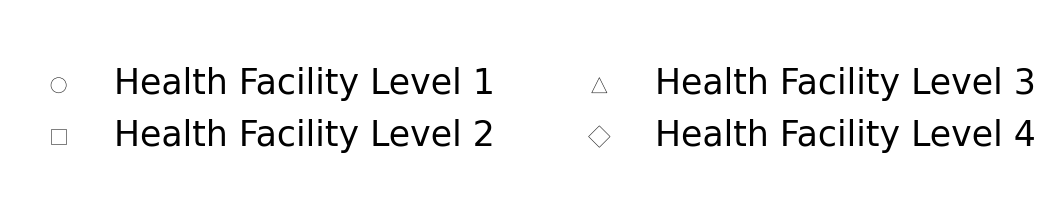

In [45]:
plot_only_hospital_legend_gray_outline("/cluster/home/gespejo/MOZ_struc_plots_Freddy/hospital_levels_legend_only_gray_outline.png")

In [8]:
import os
import matplotlib.pyplot as plt

def plot_only_school_legend(output_path):
    fig, ax = plt.subplots(figsize=(4, 2))
    fig.patch.set_alpha(0)        # transparent figure background
    ax.axis('off')

    # dummy handle for legend
    handle = ax.scatter([], [], color='blue', edgecolor='blue', s=120, alpha=0.9)

    ax.legend([handle], ["Disrupted Schools"],
              loc='center', frameon=False,      # <-- no legend border
              fontsize=25)

    os.makedirs(os.path.dirname(output_path), exist_ok=True)
    plt.tight_layout(pad=0)
    plt.savefig(output_path, dpi=2000, bbox_inches='tight', transparent=True)
    plt.close()

# Example
plot_only_school_legend("/cluster/home/gespejo/MOZ_struc_plots_Freddy/schools_legend_only.png")

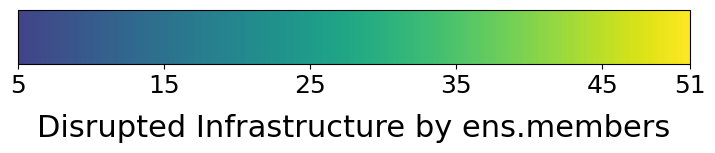

In [33]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
from matplotlib.colors import Normalize, ListedColormap

def truncate_colormap(cmap_name='viridis', minval=0.2, maxval=1.0, n=256):
    cmap = plt.get_cmap(cmap_name)
    return ListedColormap(cmap(np.linspace(minval, maxval, n)))

def save_and_show_road_disruption_colorbar(
    filename='/cluster/home/gespejo/MOZ_struc_plots_Freddy/legend_disrupted_roads.png'
):
    cmap = truncate_colormap('viridis', 0.2, 1.0)
    norm = Normalize(vmin=5, vmax=51)

    # Create a figure and a dedicated axis with generous bottom margin
    fig = plt.figure(figsize=(8, 1.8))
    cax = fig.add_axes([0.08, 0.55, 0.84, 0.3])  # [left, bottom, width, height]

    cb = mpl.colorbar.ColorbarBase(
        cax,
        cmap=cmap,
        norm=norm,
        orientation='horizontal',
        ticks=[5, 15, 25, 35, 45, 51]
    )
    cb.set_label('Disrupted Infrastructure by ens.members', fontsize=22, labelpad=12)
    cb.ax.tick_params(labelsize=18)

    # Save tightly so nothing is cut off
    fig.savefig(filename, dpi=2000, bbox_inches='tight', pad_inches=0.02)
    plt.show()
    plt.close(fig)

# Call it
save_and_show_road_disruption_colorbar()